In [ ]:
# Paths (relative to the repository root, so the notebooks run on any machine)
# Expected layout:  <repo>/notebooks/ (this file), <repo>/data/, <repo>/models/,
#                   <repo>/figures/, <repo>/results/, <repo>/feature_importance/
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT / "models"
FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
FI_DIR = ROOT / "feature_importance"
for _d in (DATA_DIR, MODELS_DIR, FIG_DIR, RESULTS_DIR, FI_DIR):
    _d.mkdir(parents=True, exist_ok=True)


In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from lightgbm import LGBMRegressor

from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    root_mean_squared_error
)

from scipy.stats import pearsonr, spearmanr

In [2]:
# Load the train/test datasets

X_train = pd.read_csv(str(DATA_DIR / "X_train1.csv"))

X_test  = pd.read_csv(str(DATA_DIR / "X_test1.csv"))

y_train = pd.read_csv(str(DATA_DIR / "y_train1.csv")).squeeze()

y_test = pd.read_csv(str(DATA_DIR / "y_test1.csv")).squeeze()

In [3]:
# verify the train/test datasets

(X_train.shape, X_test.shape)

((21440, 1442), (5361, 1442))

In [4]:
cv_splitter = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [5]:
# Identifing the feature groups

cell_columns = [
    c for c in X_train.columns
    if c.startswith("Cell_line_")
]

metal_onehot = [
    c for c in X_train.columns
    if c.startswith("Metal_")
]

metal_numeric = [
    "Atomic_number",
    "Valence_e",
    "Oxidation_state"
]

charge_column = [
    "Charge_complex"
]

In [6]:
# Ligand descriptors

ligand_columns = [

    c for c in X_train.columns

    if c not in (

        cell_columns
        + metal_onehot
        + metal_numeric
        + charge_column
    )
]

In [7]:
print(len(ligand_columns))
print(len(cell_columns))
print(len(metal_onehot))

681
753
4


In [8]:
# Create 5 feature sets

feature_sets = {

    "Model 1":
        ligand_columns,

    "Model 2":
        ligand_columns +
        cell_columns,

    "Model 3":
        ligand_columns +
        metal_numeric +
        metal_onehot,

    "Model 4":
        ligand_columns +
        metal_numeric +
        metal_onehot +
        charge_column,

    "Model 5":
        list(X_train.columns)

}

In [9]:
# Verify the every model

for name, cols in feature_sets.items():

    print(name, len(cols))

Model 1 681
Model 2 1434
Model 3 688
Model 4 689
Model 5 1442


In [10]:
# Create an Evaluate_ablation function

def evaluate_ablation(
        X_train_sub,
        X_test_sub,
        y_train,
        y_test,
        model_name,
        params
):

    # Create model
    model = LGBMRegressor(
        random_state=42,
        verbose=-1,
        n_jobs=-1,
        **params
    )
          
    # --------------------------
    # 5-fold Cross Validation
    # --------------------------

    cv = cross_validate(
        model,
        X_train_sub,
        y_train,
        cv=cv_splitter,
        scoring=("r2",
                 "neg_root_mean_squared_error",
                 "neg_mean_absolute_error"),
        n_jobs=-1
    )

    # --------------------------
    # Train model
    # --------------------------

    model.fit(X_train_sub, y_train)

    # --------------------------
    # Predictions
    # --------------------------

    train_pred = model.predict(X_train_sub)
    test_pred = model.predict(X_test_sub)

    # --------------------------
    # Metrics
    # --------------------------

    result = {

        "Model": model_name,

        "Train R²": r2_score(y_train, train_pred),
        "Test R²": r2_score(y_test, test_pred),

        "Train RMSE": root_mean_squared_error(y_train, train_pred),
        "Test RMSE": root_mean_squared_error(y_test, test_pred),

        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),

        "Test Pearson r":
            pearsonr(y_test, test_pred)[0],

        "Test Spearman ρ":
            spearmanr(y_test, test_pred)[0],

        "CV R²":
            cv["test_r2"].mean(),

        "CV R² SD":
            cv["test_r2"].std(),

        "CV RMSE":
            -cv["test_neg_root_mean_squared_error"].mean(),

        "CV RMSE SD":
            cv["test_neg_root_mean_squared_error"].std(),

        "CV MAE":
            -cv["test_neg_mean_absolute_error"].mean(),

        "CV MAE SD":
            cv["test_neg_mean_absolute_error"].std()

    }

    return result

In [11]:
# Using the CatBoost hyperparameters

best_params = {
    "n_estimators": 1000,
    "learning_rate": 0.05,
    "max_depth": 9,
    "num_leaves": 70,
    "subsample": 0.8,
    "colsample_bytree": 0.6,
    "min_child_samples": 10
}

In [12]:
# Run the ablation study

ablation_results = []

for model_name, columns in feature_sets.items():

    print(f"Running {model_name}...")

    result = evaluate_ablation(

        X_train[columns],
        X_test[columns],

        y_train,
        y_test,

        model_name,

        best_params

    )

    ablation_results.append(result)

Running Model 1...
Running Model 2...
Running Model 3...
Running Model 4...
Running Model 5...


In [13]:
# Create a ablation table

ablation_results = pd.DataFrame(ablation_results)

ablation_results = ablation_results.round(4)

ablation_results

,Model,Train R²,Test R²,Train RMSE,Test RMSE,Train MAE,Test MAE,Test Pearson r,Test Spearman ρ,CV R²,CV R² SD,CV RMSE,CV RMSE SD,CV MAE,CV MAE SD
0,Model 1,0.8498,0.7133,0.3116,0.4198,0.2044,0.2841,0.8466,0.8411,0.6935,0.0150,0.4450,0.0115,0.3039,0.0062
1,Model 2,0.9306,0.7894,0.2118,0.3598,0.1439,0.2550,0.8888,0.8852,0.7732,0.0060,0.3829,0.0065,0.2699,0.0042
2,Model 3,0.8606,0.7238,0.3002,0.4120,0.1980,0.2796,0.8527,0.8465,0.7038,0.0144,0.4374,0.0112,0.2986,0.0056
3,Model 4,0.8606,0.7250,0.3002,0.4111,0.1979,0.2790,0.8534,0.8472,0.7048,0.0139,0.4368,0.0107,0.2982,0.0051
4,Model 5,0.9354,0.8011,0.2044,0.3496,0.1398,0.2486,0.8954,0.8913,0.7845,0.0055,0.3733,0.0069,0.2651,0.0044


In [14]:
# Save the ablation table

ablation_results.to_csv(
    str(RESULTS_DIR / "Ablation_Table_LightGBM.csv"),
    index=False
)

In [15]:
# Visualization of the ablation study

# Create shorter name for the x-axis

plot_df = ablation_results.copy()

plot_df["Model"] = [
    "M1",
    "M2",
    "M3",
    "M4",
    "M5"
]

In [16]:
# Create a plotting function

def plot_ablation(
    ax,
    x,
    y,
    ylabel,
    title,
    yerr=None,
    value_offset=0.003,
    color="steelblue",
    edgecolor="black",
    alpha=0.9
):
    """
    Plot one ablation panel.
    """

    bars = ax.bar(
        x,
        y,
        color=color,
        edgecolor=edgecolor,
        alpha=alpha,
        linewidth=1.2,
        yerr=yerr,
        capsize=4
    )

    ax.set_ylabel(ylabel, fontsize=14)
    ax.set_title(title, fontsize=15, fontweight="bold")

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )
    
    ax.tick_params(
        axis="both",
        labelsize=11
    )

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + value_offset,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

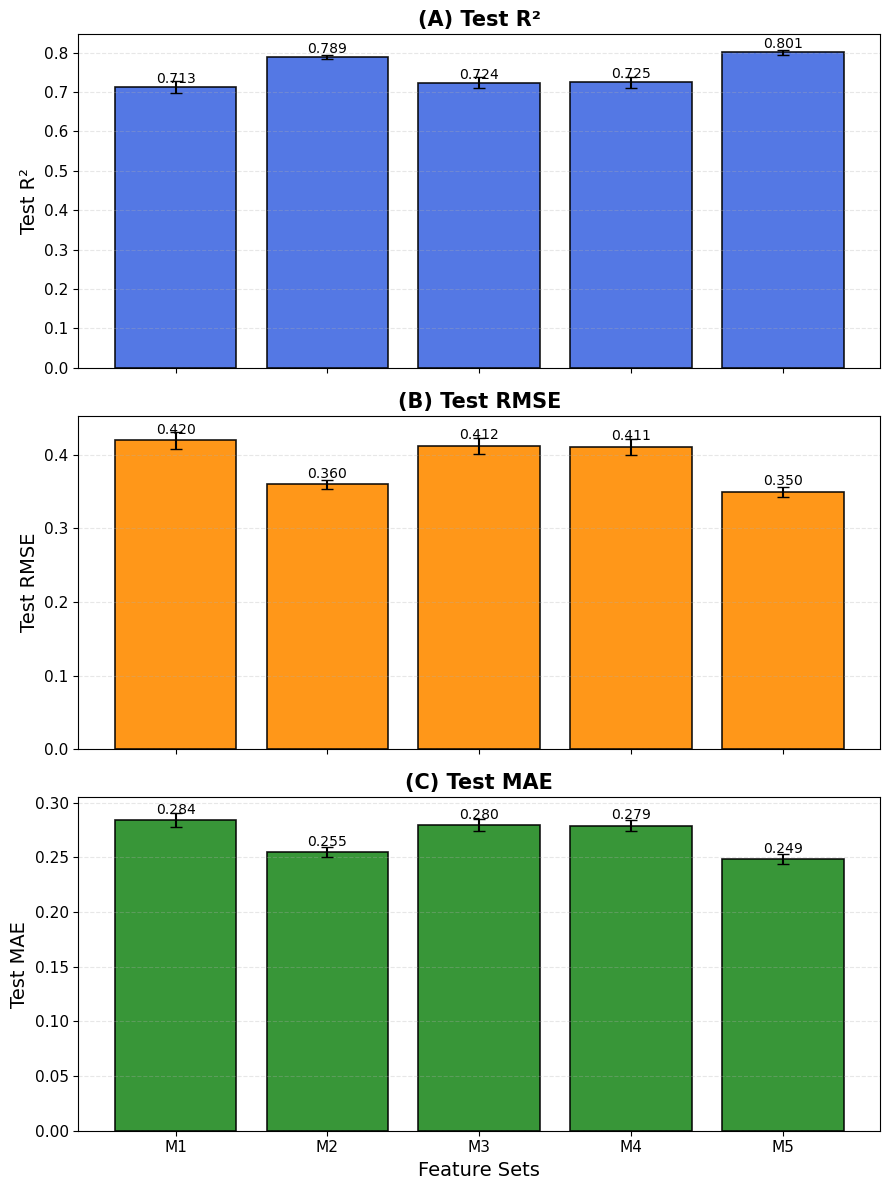

In [17]:
# Create a figure

fig, axes = plt.subplots(
    3,
    1,
    figsize=(9,12),
    sharex=True
)

# -------- Panel A --------
plot_ablation(
    ax=axes[0],
    x=plot_df["Model"],
    y=plot_df["Test R²"],
    ylabel="Test R²",
    title="(A) Test R²",
    yerr=plot_df["CV R² SD"],
    value_offset=0.003,
    color="royalblue"
)

# -------- Panel B --------
plot_ablation(
    ax=axes[1],
    x=plot_df["Model"],
    y=plot_df["Test RMSE"],
    ylabel="Test RMSE",
    title="(B) Test RMSE",
    yerr=plot_df["CV RMSE SD"],
    value_offset=0.005,
    color="darkorange"
)

# -------- Panel C --------
plot_ablation(
    ax=axes[2],
    x=plot_df["Model"],
    y=plot_df["Test MAE"],
    ylabel="Test MAE",
    title="(C) Test MAE",
    yerr=plot_df["CV MAE SD"],
    value_offset=0.003,
    color="forestgreen"
)

axes[2].set_xlabel("Feature Sets", fontsize=14)

plt.tight_layout()
# save the figure 

plt.savefig(
    str(FIG_DIR / "Ablation_Study_2.png"),
    dpi=600,
    bbox_inches="tight"
)
plt.show()

In [18]:
#Creating horizontal figure

def plot_ablation(
    ax,
    x,
    y,
    ylabel,
    title,
    yerr=None,
    value_offset=0.003,
    color="steelblue"
):

    bars = ax.bar(
        x,
        y,
        color=color,
        edgecolor="black",
        linewidth=1.2,
        yerr=yerr,
        capsize=4
    )

    ax.set_ylabel(
        ylabel,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.tick_params(
        axis="both",
        labelsize=11
    )

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + value_offset,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

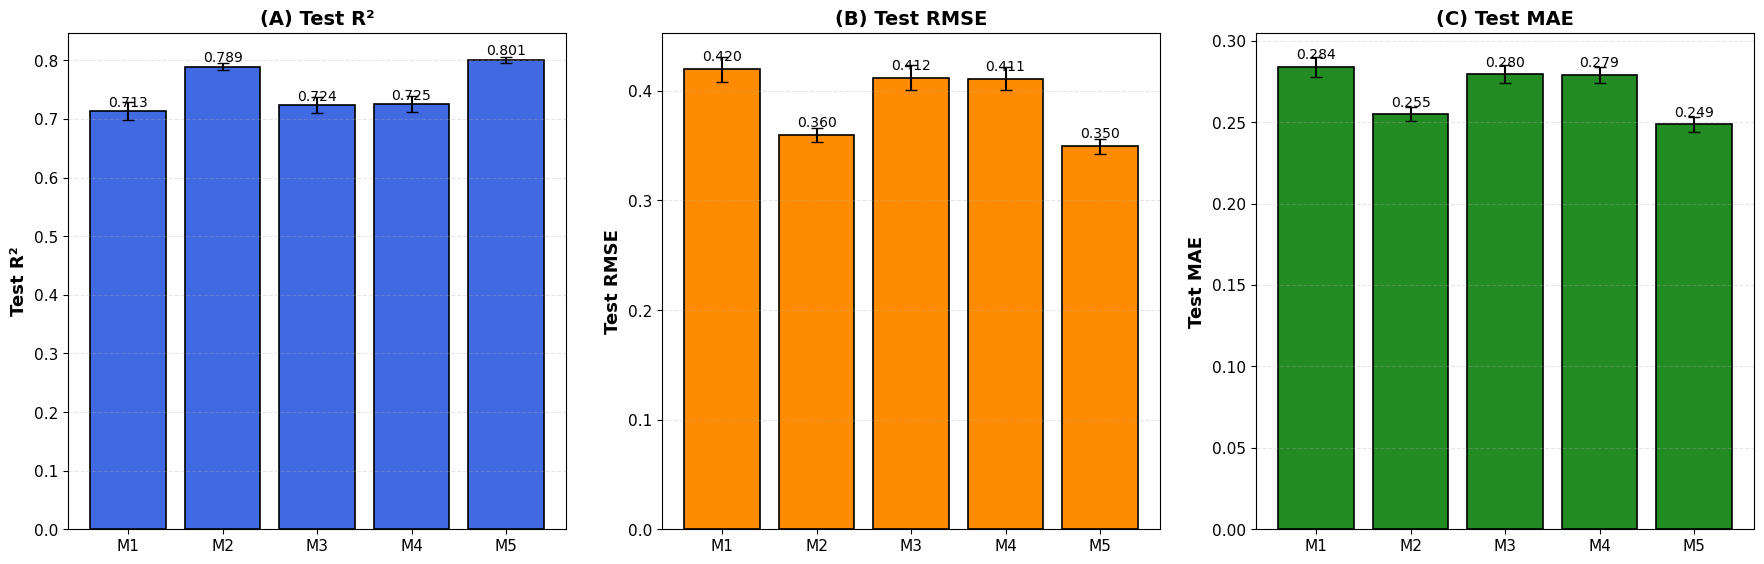

In [19]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18,6)
)

# Panel A

plot_ablation(
    ax=axes[0],
    x=plot_df["Model"],
    y=plot_df["Test R²"],
    ylabel="Test R²",
    title="(A) Test R²",
    yerr=plot_df["CV R² SD"],
    value_offset=0.003,
    color="royalblue"
)

# panel B

plot_ablation(
    ax=axes[1],
    x=plot_df["Model"],
    y=plot_df["Test RMSE"],
    ylabel="Test RMSE",
    title="(B) Test RMSE",
    yerr=plot_df["CV RMSE SD"],
    value_offset=0.005,
    color="darkorange"
)

# panel C 

plot_ablation(
    ax=axes[2],
    x=plot_df["Model"],
    y=plot_df["Test MAE"],
    ylabel="Test MAE",
    title="(C) Test MAE",
    yerr=plot_df["CV MAE SD"],
    value_offset=0.003,
    color="forestgreen"
)

for ax in axes:

    ax.tick_params(
        axis="x",
        labelrotation=0
    )

plt.tight_layout(pad=2.0)

plt.savefig(
    str(FIG_DIR / "Ablation_Study_Horizontal_2.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()   

In [20]:
def plot_ablation(
    ax,
    x,
    y,
    ylabel,
    title,
    color,
    yerr=None,
    value_offset=0.003
):
    """
    Draw one panel of the ablation study.
    """

    bars = ax.bar(
        x,
        y,
        color=color,
        edgecolor="black",
        linewidth=1.2,
        width=0.65,
        yerr=yerr,
        capsize=4,
        error_kw={
            "elinewidth":1.2,
            "ecolor":"black"
        }
    )

    # Titles
    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        pad=12
    )

    # Axis labels
    ax.set_ylabel(
        ylabel,
        fontsize=15,
        fontweight="bold"
    )

    # Tick labels
    ax.tick_params(
        axis="both",
        labelsize=11
    )

    # Grid
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.35
    )

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Values above bars
    for i, bar in enumerate (bars):

        height = bar.get_height()

        error = 0 if yerr is None else yerr.iloc[i]

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + error + value_offset,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

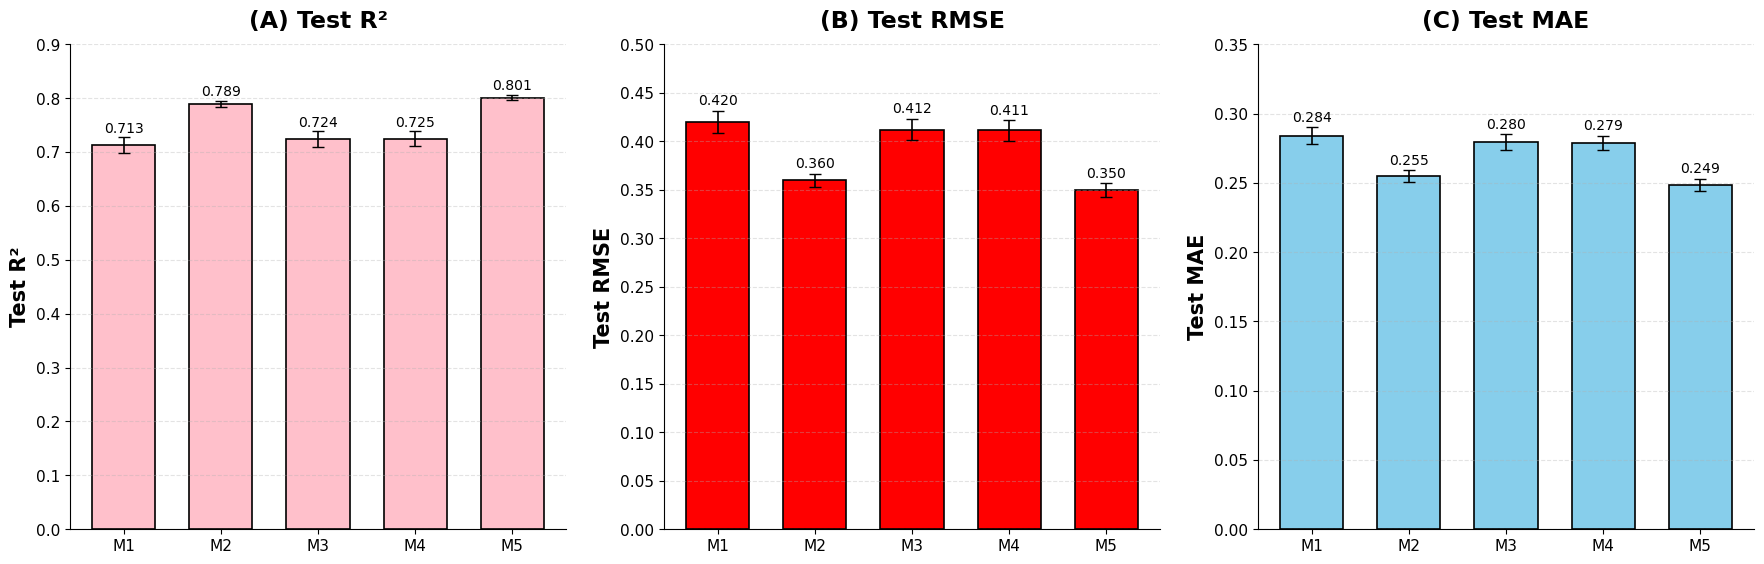

In [22]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18,6)
)

# Panel A

plot_ablation(

    ax=axes[0],

    x=plot_df["Model"],

    y=plot_df["Test R²"],

    ylabel="Test R²",

    title="(A) Test R²",

    color="pink",

    yerr=plot_df["CV R² SD"],

    value_offset=0.003

)

# Panel B

plot_ablation(

    ax=axes[1],

    x=plot_df["Model"],

    y=plot_df["Test RMSE"],

    ylabel="Test RMSE",

    title="(B) Test RMSE",

    color="red",

    yerr=plot_df["CV RMSE SD"],

    value_offset=0.003

)

# Panel C

plot_ablation(

    ax=axes[2],

    x=plot_df["Model"],

    y=plot_df["Test MAE"],

    ylabel="Test MAE",

    title="(C) Test MAE",

    color="skyblue",

    yerr=plot_df["CV MAE SD"],

    value_offset=0.002

)

axes[0].set_ylim(0.0, 0.9)
axes[1].set_ylim(0.0, 0.5)
axes[2].set_ylim(0.0, 0.35)

axes[0].yaxis.set_major_locator(MultipleLocator(0.1))
axes[1].yaxis.set_major_locator(MultipleLocator(0.05))
axes[2].yaxis.set_major_locator(MultipleLocator(0.05))

plt.tight_layout(
    pad=2.0
)

plt.savefig(

    str(FIG_DIR / "Ablation_Study_horizontal_withoutspines_3.png"),

    dpi=600,

    bbox_inches="tight"
)

plt.show()